In [2]:
pip install gensim

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: C:\Users\Avadhut\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [5]:
import numpy as np
import pandas as pd
import re

from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
import matplotlib.pyplot as plt

In [6]:
data = pd.read_csv("IMDB Dataset.csv")

print(data.head())

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [30]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z]", " ",text)
    return text.split()

sentences = data["review"].apply(clean_text)

print(sentences.head())

0    [one, of, the, other, reviewers, has, mentione...
1    [a, wonderful, little, production, the, filmin...
2    [i, thought, this, was, a, wonderful, way, to,...
3    [basically, there, s, a, family, where, a, lit...
4    [petter, mattei, s, love, in, the, time, of, m...
Name: review, dtype: object


In [31]:
X = sentences
y = data["sentiment"]

encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [32]:
X_train,X_test,y_train,y_test= train_test_split(
    X,y,
    test_size=0.2,random_state=42,
     stratify=y
)

In [33]:
cbow = Word2Vec(
    sentences=X_train,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    epochs=5
)

In [34]:
def get_vector(words):
    vectors=[cbow.wv[word] for word in words if word in cbow.wv]

    if(len(vectors)==0):
        return np.zeros(100)

    return np.mean(vectors,axis=0)

X_train = np.array([get_vector(words) for words in X_train])
X_test = np.array([get_vector(words) for words in X_test])

print(X_train.shape)
print(X_test.shape)

(40000, 100)
(10000, 100)


In [35]:
model = keras.Sequential([
    keras.Input(shape=(100,)),
    keras.layers.Dense(64,activation="relu"),
    keras.layers.Dense(32,activation="relu"),
    keras.layers.Dense(1,activation="sigmoid")
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                      │ (None, 64)                  │           6,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 8,577 (33.50 KB)

 Trainable params: 8,577 (33.50 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
model.compile(
    optimizer="adam",
    loss = "binary_crossentropy",
    metrics=["accuracy"]
)

In [37]:
history = model.fit(
    X_train,y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8104 - loss: 0.4166 - val_accuracy: 0.8365 - val_loss: 0.3712
Epoch 2/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8391 - loss: 0.3704 - val_accuracy: 0.8354 - val_loss: 0.3674
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8429 - loss: 0.3626 - val_accuracy: 0.8443 - val_loss: 0.3501
Epoch 4/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8426 - loss: 0.3592 - val_accuracy: 0.8459 - val_loss: 0.3536
Epoch 5/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8445 - loss: 0.3560 - val_accuracy: 0.8494 - val_loss: 0.3502
Epoch 6/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8475 - loss: 0.3531 - val_accuracy: 0.8495 - val_loss: 0.3448
Epoch 7/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8478 - loss: 0.3483 - val_accuracy: 0.8430 - val_loss: 0.3532
Epoch 8/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8490 - loss: 0.3484 - 

In [38]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8492 - loss: 0.3439    
Test Loss: 0.343865305185318
Test Accuracy: 0.8492000102996826


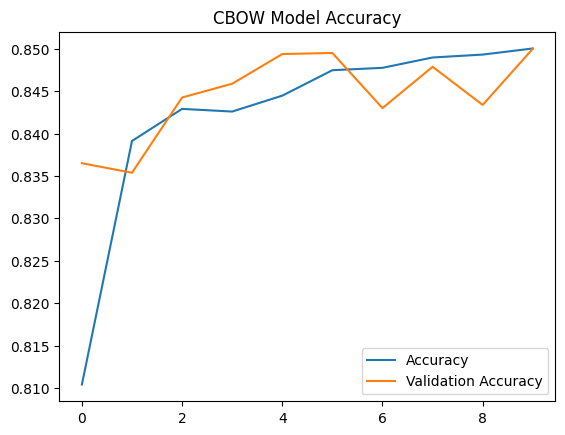

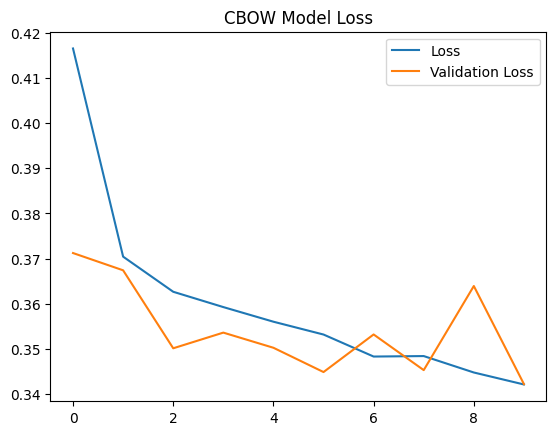

In [39]:
plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CBOW Model Accuracy")
plt.legend()
plt.show()


plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CBOW Model Loss")
plt.legend()
plt.show()

In [40]:
predictions = model.predict(X_test)

y_pred = (predictions > 0.5).astype(int)

print("Actual Labels:   ", y_test[:10])
print("Predicted Labels:", y_pred[:10].flatten())

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
Actual Labels:    [0 0 1 0 0 0 0 0 0 0]
Predicted Labels: [0 1 1 0 0 0 0 0 1 0]


In [41]:
for i in range(10):
    actual = encoder.inverse_transform([y_test[i]])[0]
    predicted = encoder.inverse_transform([y_pred[i][0]])[0]

    print("Review:", " ".join(data["review"].iloc[i].split()[:15]))
    print("Actual Sentiment:", actual)
    print("Predicted Sentiment:", predicted)
    print("----------------------------")

Review: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll
Actual Sentiment: negative
Predicted Sentiment: negative
----------------------------
Review: A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion
Actual Sentiment: negative
Predicted Sentiment: positive
----------------------------
Review: I thought this was a wonderful way to spend time on a too hot summer
Actual Sentiment: positive
Predicted Sentiment: positive
----------------------------
Review: Basically there's a family where a little boy (Jake) thinks there's a zombie in his
Actual Sentiment: negative
Predicted Sentiment: negative
----------------------------
Review: Petter Mattei's "Love in the Time of Money" is a visually stunning film to watch.
Actual Sentiment: negative
Predicted Sentiment: negative
----------------------------
Review: Probably my all-time favorite movie, a story of selflessness, sacrifice and dedication to 